In [1]:
# Librerías necesarias 
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

imagen  | umbral_binario

img_01  | 150

img_02  | 120

img_03  | 110

img_04  | 120

img_05  | 120

img_06  | 110

img_07  | 100

img_08  | 130

img_09  | 115

img_10  | 115

img_11  | 140

img_12  | 100

In [12]:
# Diccionario de imagenes y umbrales optimos
image_thresholds = {"img01.png": 150,
                    "img02.png": 120,
                    "img03.png": 110,
                    "img04.png": 120,
                    "img05.png": 120,
                    "img06.png": 110,
                    "img07.png": 100,
                    "img08.png": 130,
                    "img09.png": 115,
                    "img10.png": 115,
                    "img11.png": 140,
                    "img12.png": 100
}

In [ ]:
# Función para cargar imágenes desde un directorio
def load_images_from_folder(folder):
    images = []
    for filename in os.listdir(folder):
        img = cv2.imread(os.path.join(folder, filename))
        if img is not None:
            images.append(img)
    return images

In [ ]:
# Cargamos la imagen original
path_imagen = './img08.png'
imagen_orig = cv2.imread(path_imagen)
# Ajuste umbral para binarizar las imagenes
umbral_binario = 130
# Ajuste umbral separación caracteres
#umbral_separacion = 0.5

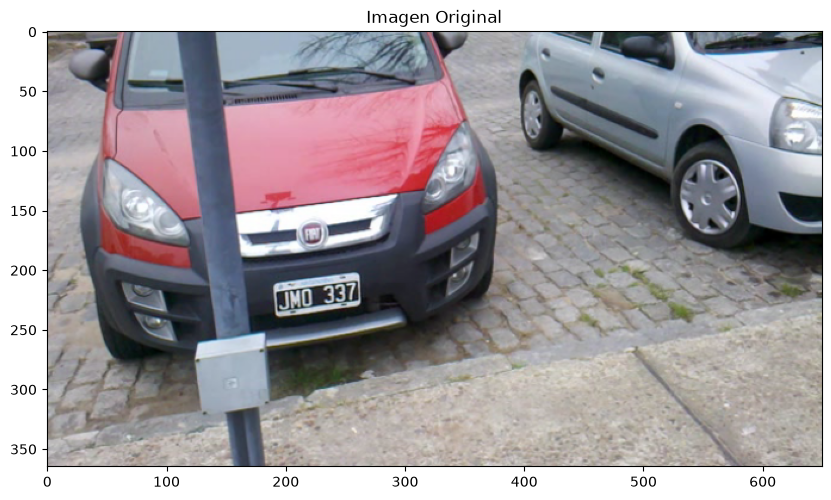

In [ ]:
# Redimensionamos a un ancho fijo de 600px para normalizar métricas de área
valor_w = 650
h_orig, w_orig = imagen_orig.shape[:2]
escala = valor_w / float(w_orig)
target_h = int(h_orig * escala)
imagen = cv2.resize(imagen_orig, (valor_w, target_h))

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
plt.title('Imagen Original')
#plt.axis('off')
plt.show()


In [4]:
# Convertimos a escala de grises
imagen_gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
"""
plt.figure(figsize=(10, 10))
plt.imshow(imagen_gris, cmap='gray')
plt.title('Imagen en Escala de Grises')
plt.axis('off')
plt.show()
"""

"\nplt.figure(figsize=(10, 10))\nplt.imshow(imagen_gris, cmap='gray')\nplt.title('Imagen en Escala de Grises')\nplt.axis('off')\nplt.show()\n"

In [5]:
# Umbralamos para aislar la patente en negro/blanco
_, imagen_binaria = cv2.threshold(imagen_gris, umbral_binario, 255, cv2.THRESH_BINARY)

"""
plt.figure(figsize=(10, 10))
plt.imshow(imagen_binaria, cmap='gray')
plt.title('Imagen Binaria')
#plt.axis('off')
plt.show()
"""

"\nplt.figure(figsize=(10, 10))\nplt.imshow(imagen_binaria, cmap='gray')\nplt.title('Imagen Binaria')\n#plt.axis('off')\nplt.show()\n"

Etiqueta 117 (Grupo de 3): Área 44 Bbox -> Base: 8 Altura:14 X:195
Etiqueta 114 (Grupo de 3): Área 90 Bbox -> Base: 9 Altura:15 X:204
Etiqueta 115 (Grupo de 3): Área 74 Bbox -> Base: 8 Altura:15 X:214
Etiqueta 109 (Grupo de 3): Área 61 Bbox -> Base: 9 Altura:15 X:232
Etiqueta 110 (Grupo de 3): Área 60 Bbox -> Base: 8 Altura:15 X:242
Etiqueta 108 (Grupo de 3): Área 43 Bbox -> Base: 8 Altura:14 X:251


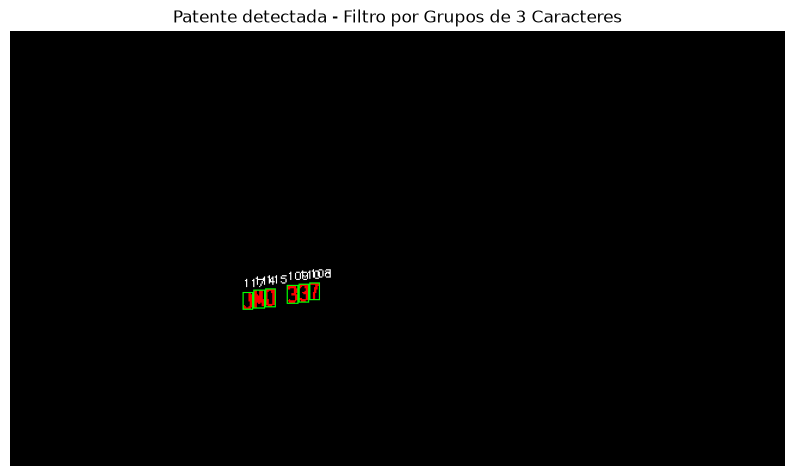

In [9]:
# Aplicamos componentes conectadas
# Filtramos las etiquetas con Area mayor a 20 y menor a 120
num_etiquetas, etiquetas, stats, _ = cv2.connectedComponentsWithStats(imagen_binaria, connectivity=8)

# Crear una imagen negra en formato RGB (alto, ancho, 3 canales)
alto, ancho = etiquetas.shape
im_final = np.zeros((alto, ancho, 3), dtype=np.uint8)

candidatos = []

for i in range(1, num_etiquetas):
    x, y, w, h, area = stats[i]
    # Filtramos por área y relación de aspecto
    if area > 22 and area < 120:
        if h/w > 1.5 and h/w < 3:
            candidatos.append((i, x, y, w, h, area))

# 1. Ordenar candidatos por la coordenada X
candidatos_ordenados = sorted(candidatos, key=lambda c: c[1])

# 2. Agrupación por cercanía usando un umbral de separación ajustable
# Definimos el umbral de separación (multiplicador del ancho del caracter para tolerancia)
umbral_separacion = 0.5
grupos = []

if candidatos_ordenados:
    grupo_actual = [candidatos_ordenados[0]]
    for c in candidatos_ordenados[1:]:
        # C_anterior: (i, x, y, w, h, area)
        c_ant = grupo_actual[-1]
        distancia_x = c[1] - (c_ant[1] + c_ant[3]) # Distancia entre el inicio del actual y el final del anterior

        # Si la distancia es mayor a 'umbral_separacion * ancho_promedio_caracter', creamos nuevo grupo
        ancho_referencia = (c[3] + c_ant[3]) / 2
        if distancia_x > (umbral_separacion * ancho_referencia):
            grupos.append(grupo_actual)
            grupo_actual = [c]
        else:
            grupo_actual.append(c)
    grupos.append(grupo_actual)

# 3. Filtrar y dibujar grupos que tengan exactamente 3 caracteres
caracteres_filtrados = []
for g in grupos:
    if len(g) == 3:
        caracteres_filtrados.extend(g)

# Dibujamos solo los caracteres que pasaron el filtro final por grupos
for i, x, y, w, h, area in caracteres_filtrados:
    # Pintar el objeto de color ROJO puro en formato RGB
    im_final[etiquetas == i] = [255, 0, 0]

    # Bounding box color verde (0, 255, 0)
    cv2.rectangle(im_final, (x, y), (x + w, y + h), (0, 255, 0), 1)

    # Texto/Etiquetas
    cv2.putText(im_final, str(i), (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.3, (255, 255, 255), 1)
    print(f"Etiqueta {i} (Grupo de 3): Área {area} Bbox -> Base: {w} Altura:{h} X:{x}")

# Mostramos únicamente la imagen final con todas las detecciones aplicadas
plt.figure(figsize=(10, 10))
plt.imshow(im_final)
plt.title('Patente detectada - Filtro por Grupos de 3 Caracteres')
plt.axis('off')
plt.show()

In [10]:
# Monitoreo de los candidatos ordenados y sus áreas
print("Candidatos ordenados por coordenada X:")
for i, x, y, w, h, area in candidatos_ordenados:
    print(f"Etiqueta {i}: Área {area} Bbox -> Base: {w} Altura:{h} X:{x}")

print("\nGrupos de caracteres detectados:")
for i, x, y, w, h, area in caracteres_filtrados:
    print(f"Etiqueta {i} (Grupo de 3): Área {area} Bbox -> Base: {w} Altura:{h} X:{x}")


Candidatos ordenados por coordenada X:
Etiqueta 117: Área 44 Bbox -> Base: 8 Altura:14 X:195
Etiqueta 114: Área 90 Bbox -> Base: 9 Altura:15 X:204
Etiqueta 115: Área 74 Bbox -> Base: 8 Altura:15 X:214
Etiqueta 109: Área 61 Bbox -> Base: 9 Altura:15 X:232
Etiqueta 110: Área 60 Bbox -> Base: 8 Altura:15 X:242
Etiqueta 108: Área 43 Bbox -> Base: 8 Altura:14 X:251
Etiqueta 6: Área 47 Bbox -> Base: 12 Altura:26 X:319
Etiqueta 96: Área 27 Bbox -> Base: 7 Altura:12 X:355
Etiqueta 71: Área 53 Bbox -> Base: 6 Altura:12 X:548
Etiqueta 73: Área 38 Bbox -> Base: 7 Altura:15 X:556

Grupos de caracteres detectados:
Etiqueta 117 (Grupo de 3): Área 44 Bbox -> Base: 8 Altura:14 X:195
Etiqueta 114 (Grupo de 3): Área 90 Bbox -> Base: 9 Altura:15 X:204
Etiqueta 115 (Grupo de 3): Área 74 Bbox -> Base: 8 Altura:15 X:214
Etiqueta 109 (Grupo de 3): Área 61 Bbox -> Base: 9 Altura:15 X:232
Etiqueta 110 (Grupo de 3): Área 60 Bbox -> Base: 8 Altura:15 X:242
Etiqueta 108 (Grupo de 3): Área 43 Bbox -> Base: 8 Altur

Recorte de la patente guardado en: imagen_patentes_detectadas\patente_img08.png


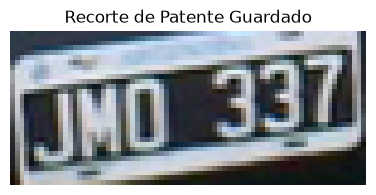

In [11]:
# Hacemos un crop de la patente detectada, imprimimos y guardamos en disco
# Crea la carpeta de destino si no existe
carpeta_salida = 'imagen_patentes_detectadas'
os.makedirs(carpeta_salida, exist_ok=True)

if caracteres_filtrados:
    # Obtener los límites extremos de todos los caracteres detectados para hacer el recorte
    x_min = min(c[1] for c in caracteres_filtrados)
    y_min = min(c[2] for c in caracteres_filtrados)
    x_max = max(c[1] + c[3] for c in caracteres_filtrados)
    y_max = max(c[2] + c[4] for c in caracteres_filtrados)

    # Añadir un pequeño margen de 5 píxeles a los lados (opcional y controlado por los límites de la imagen)
    margen = 5
    y_start = max(0, y_min - margen)
    y_end = min(imagen.shape[0], y_max + margen)
    x_start = max(0, x_min - margen)
    x_end = min(imagen.shape[1], x_max + margen)

    # Recortar de la imagen normalizada (o puedes cambiar a 'imagen_orig' ajustando por la escala si lo prefieres)
    recorte_patente = imagen[y_start:y_end, x_start:x_end]

    # Determinar el nombre dinámico del archivo basado en el path original
    path_orig = path_imagen # Ruta de referencia actual
    nombre_archivo_orig = os.path.basename(path_orig)
    nombre_sin_ext, _ = os.path.splitext(nombre_archivo_orig)

    # Construir el nombre de destino: patente_imgxx.png
    nombre_salida = f"patente_{nombre_sin_ext}.png"
    ruta_completa_salida = os.path.join(carpeta_salida, nombre_salida)

    # Guardar la imagen recortada
    cv2.imwrite(ruta_completa_salida, recorte_patente)
    print(f"Recorte de la patente guardado en: {ruta_completa_salida}")

    # Mostrar el recorte obtenido
    plt.figure(figsize=(5, 2))
    plt.imshow(cv2.cvtColor(recorte_patente, cv2.COLOR_BGR2RGB))
    plt.title('Recorte de Patente Guardado')
    plt.axis('off')
    plt.show()
else:
    print("No se detectaron caracteres válidos para realizar el recorte.")